In [1]:
import os, sys, json, time, random, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, roc_curve

try:
    import timm
except ImportError:
    os.system("pip install -q --no-deps timm huggingface_hub safetensors")
    import timm

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
else:
    os.system(f"cd {REPO_DIR} && git pull")
sys.path.append(REPO_DIR)
try:
    import dfx_model, dfx_data
except ImportError as e:
    raise ImportError("dfx_model.py / dfx_data.py are not in the GitHub repo root yet. Push them, then re-run.") from e

INPUT_ROOT = "/kaggle/input"

# ---------------- configuration (starting points, not tuned) ----------------
SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
PRETRAINED = True
STAGE1_EPOCHS, STAGE1_LR = 2, 1e-3      # head only
STAGE2_EPOCHS, STAGE2_LR = 10, 1e-4     # whole network, cosine schedule
WEIGHT_DECAY = 1e-4
PATIENCE = 3                            # early stopping on validation ROC-AUC
RUN_OVERFIT_TEST = True
DEBUG_SUBSET = None                      # set to None for the real run

def find_one(name, roots):
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda" or DEBUG_SUBSET, "No GPU: set the Accelerator to GPU T4 (or use DEBUG_SUBSET for a CPU smoke test)."
set_seed(SEED)
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
      "| torch", torch.__version__, "| timm", timm.__version__)
if DEBUG_SUBSET:
    print(f"\n*** DEBUG MODE: only {DEBUG_SUBSET} train faces. Results from this run are NOT usable. ***")

Cloning into '/kaggle/working/repo'...


device: cuda | Tesla T4 | torch 2.11.0+cu128 | timm 1.0.29


In [2]:
# ============================================================
# LOAD THE FROZEN MANIFEST (hash-verified) AND SELECT TRAIN / VAL
# ============================================================
manifest_csv = find_one("faces_manifest.csv", [REPO_DIR, INPUT_ROOT])
meta_json = find_one("manifest_meta.json", [REPO_DIR, INPUT_ROOT])
meta = json.load(open(meta_json))
assert sha256(manifest_csv) == meta["manifest_sha256"], "faces_manifest.csv does not match manifest_meta.json (edited or wrong version)"
m = pd.read_csv(manifest_csv)
CLEAN_ROOT = dfx_data.resolve_dir("step5_faces", INPUT_ROOT)
print("manifest:", manifest_csv, "| rows:", len(m), "| sha256 verified")
print("clean crops:", CLEAN_ROOT)

train_df = m[m["role"] == "train"].reset_index(drop=True)
val_df = m[m["role"] == "val"].reset_index(drop=True)
assert set(train_df["dataset"]) == {"FaceForensics++"} and set(val_df["dataset"]) == {"FaceForensics++"}, "train/val must be FF++ only"
assert not (set(train_df["video_id"]) & set(val_df["video_id"])), "a video is in both train and val"

if DEBUG_SUBSET:
    def take(df, n):
        return df.groupby("label", group_keys=False).apply(lambda g: g.sample(min(len(g), n // 2), random_state=SEED)).reset_index(drop=True)
    train_df, val_df = take(train_df, DEBUG_SUBSET), take(val_df, max(DEBUG_SUBSET // 4, 16))

print(pd.concat([train_df.assign(s="train"), val_df.assign(s="val")]).groupby(["s", "label_name"]).agg(
    faces=("face_id", "size"), videos=("video_id", "nunique")).unstack(fill_value=0))

missing = [r for r in pd.concat([train_df, val_df])["face_rel"] if not os.path.exists(os.path.join(CLEAN_ROOT, r))]
assert not missing, f"{len(missing)} crops missing, e.g. {missing[:2]}"

# class weight for the positive class, from the TRAIN split only
n_real, n_fake = int((train_df["label"] == 0).sum()), int((train_df["label"] == 1).sum())
POS_WEIGHT = n_real / n_fake
print(f"train REAL {n_real} | FAKE {n_fake} | pos_weight {POS_WEIGHT:.4f}")

manifest: /kaggle/input/datasets/mugdhanaik/faces-manifests/faces_manifest.csv | rows: 28184 | sha256 verified
clean crops: /kaggle/input/notebooks/mugdhanaik/step5-regenerate/step5_faces
           faces       videos     
label_name  FAKE  REAL   FAKE REAL
s                                 
train       5850  5891    195  198
val          897   900     30   30
train REAL 5891 | FAKE 5850 | pos_weight 1.0070


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
{'timm_name': 'legacy_xception', 'timm_version': '1.0.29', 'pretrained': True, 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'input_size': 299}
batch: (32, 3, 299, 299) | REAL/FAKE in batch: 14 / 18 | pixel mean/std after normalise: -0.01 / 0.45


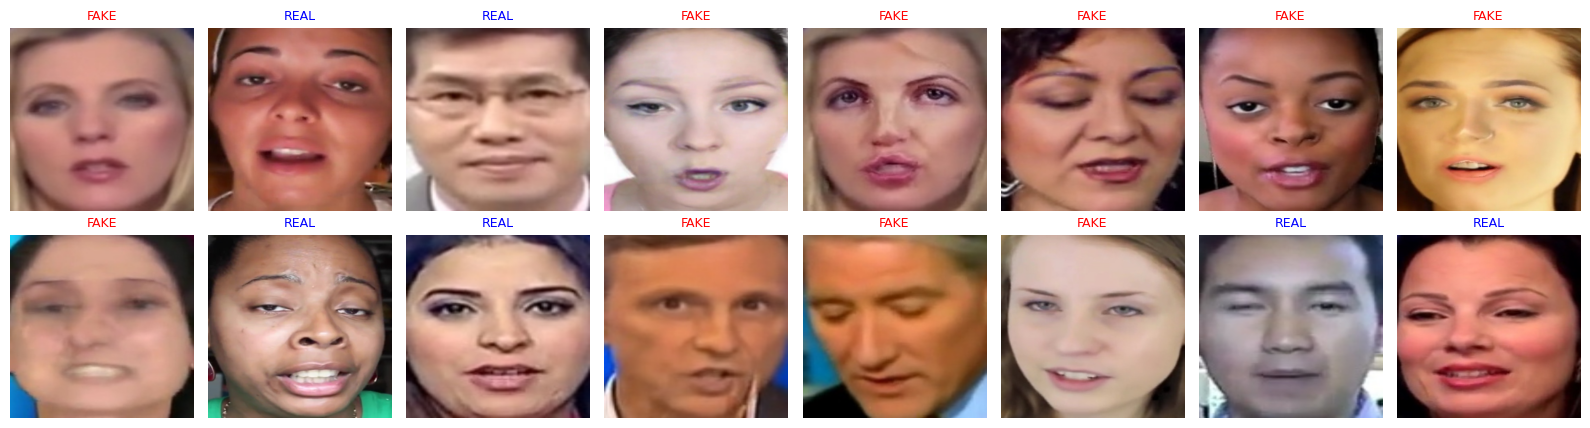

In [3]:
# ============================================================
# 2.3: MODEL, LOADERS, AND A LOOK AT ONE BATCH
# ============================================================
model, info = dfx_model.build_xception(pretrained=PRETRAINED)
model = model.to(device)
MEAN, STD, SIZE = info["mean"], info["std"], dfx_model.INPUT_SIZE
print(info)

train_loader = dfx_data.make_loader(train_df, CLEAN_ROOT, MEAN, STD, SIZE, train=True, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED)
val_loader = dfx_data.make_loader(val_df, CLEAN_ROOT, MEAN, STD, SIZE, train=False, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

x, y, fid = next(iter(train_loader))
print("batch:", tuple(x.shape), "| REAL/FAKE in batch:", int((y == 0).sum()), "/", int((y == 1).sum()),
      "| pixel mean/std after normalise: %.2f / %.2f" % (x.mean().item(), x.std().item()))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, xi, yi, fi in zip(axes.ravel(), x, y, fid):
    ax.imshow(dfx_data.denormalize(xi, MEAN, STD)); ax.axis("off")
    ax.set_title(("FAKE" if yi > 0.5 else "REAL"), color=("red" if yi > 0.5 else "blue"), fontsize=9)
plt.tight_layout(); plt.savefig("/kaggle/working/batch_check.png", dpi=100); plt.show()
assert x.shape[1:] == (3, SIZE, SIZE)

In [4]:
# ============================================================
# TRAINING MACHINERY
# ============================================================
use_amp = device.type == "cuda"
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp)

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT], device=device))

def train_epoch(model, loader, opt, bn_eval):
    model.train()
    if bn_eval:
        model.eval()                      # stage 1: keep the frozen backbone's BatchNorm statistics untouched
    total, n = 0.0, 0
    for x, y, _ in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with autocast():
            logit = model(x).squeeze(1)
        loss = criterion(logit.float(), y)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, probs, labels, ids = 0.0, [], [], []
    for x, y, fid in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            logit = model(x).squeeze(1)
        logit = logit.float()
        loss_sum += criterion(logit, y).item() * len(y)
        probs.append(torch.sigmoid(logit).cpu().numpy()); labels.append(y.cpu().numpy()); ids += list(fid)
    probs, labels = np.concatenate(probs), np.concatenate(labels)
    return {"loss": loss_sum / len(labels), "auc": float(roc_auc_score(labels, probs)),
            "acc": float(((probs >= 0.5) == (labels > 0.5)).mean()), "probs": probs, "labels": labels, "ids": ids}

print("ready | AMP:", use_amp)

ready | AMP: True


In [5]:
# ============================================================
# PIPELINE TEST: the model must be able to overfit a tiny set (otherwise the pipeline is broken)
# ============================================================
if RUN_OVERFIT_TEST:
    t_model, _ = dfx_model.build_xception(pretrained=PRETRAINED)
    t_model = t_model.to(device)
    tiny = train_df.groupby("label_name", group_keys=False).head(16).reset_index(drop=True)
    tiny_loader = dfx_data.make_loader(tiny, CLEAN_ROOT, MEAN, STD, SIZE, train=True, batch_size=16, num_workers=0, seed=SEED)
    opt = torch.optim.AdamW(t_model.parameters(), lr=3e-4)
    losses = []
    for ep in range(15):
        losses.append(train_epoch(t_model, tiny_loader, opt, bn_eval=False))
    print("overfit-test loss by epoch:", [round(v, 3) for v in losses[::3]], "->", round(losses[-1], 3))
    assert losses[-1] < 0.25, "the model cannot overfit 32 images: check labels, normalisation and learning rate before training"
    print("PASS: the pipeline can learn")
    del t_model, opt
    if device.type == "cuda":
        torch.cuda.empty_cache()

overfit-test loss by epoch: [0.594, 0.088, 0.026, 0.019, 0.007] -> 0.004
PASS: the pipeline can learn


In [6]:
# ============================================================
# TRAIN: stage 1 (head only), then stage 2 (all layers, early stopping on val ROC-AUC)
# ============================================================
OUT = "/kaggle/working/p2_train"
os.makedirs(OUT, exist_ok=True)
BEST, LAST = os.path.join(OUT, "best.pt"), os.path.join(OUT, "last.pt")
log, best_auc, best_epoch, bad = [], -1.0, -1, 0

def save_ckpt(path, epoch):
    torch.save({"state_dict": model.state_dict(), "epoch": epoch, "info": info}, path)

def record(epoch, stage, tr_loss, ev, lr, t0):
    global best_auc, best_epoch, bad
    log.append({"epoch": epoch, "stage": stage, "train_loss": round(tr_loss, 4), "val_loss": round(ev["loss"], 4),
                "val_auc": round(ev["auc"], 4), "val_acc": round(ev["acc"], 4), "lr": lr, "seconds": round(time.time() - t0, 1)})
    print(log[-1])
    if ev["auc"] > best_auc:
        best_auc, best_epoch, bad = ev["auc"], epoch, 0
        save_ckpt(BEST, epoch)
        return False
    bad += 1
    return stage == 2 and bad >= PATIENCE          # True = stop

epoch = 0
# ---- stage 1 ----
n_train_params = dfx_model.set_stage(model, 1)
print("stage 1: trainable parameters", n_train_params)
opt = torch.optim.AdamW(dfx_model.head_parameters(model), lr=STAGE1_LR, weight_decay=WEIGHT_DECAY)
for _ in range(STAGE1_EPOCHS):
    epoch += 1; t0 = time.time()
    tr = train_epoch(model, train_loader, opt, bn_eval=True)
    record(epoch, 1, tr, evaluate(model, val_loader), STAGE1_LR, t0)

# ---- stage 2 ----
n_train_params = dfx_model.set_stage(model, 2)
print("stage 2: trainable parameters", n_train_params)
opt = torch.optim.AdamW(model.parameters(), lr=STAGE2_LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=STAGE2_EPOCHS)
bad = 0
for _ in range(STAGE2_EPOCHS):
    epoch += 1; t0 = time.time()
    tr = train_epoch(model, train_loader, opt, bn_eval=False)
    stop = record(epoch, 2, tr, evaluate(model, val_loader), opt.param_groups[0]["lr"], t0)
    sched.step()
    if stop:
        print(f"early stopping: no val-AUC gain for {PATIENCE} epochs"); break
save_ckpt(LAST, epoch)
print(f"\nbest val AUC {best_auc:.4f} at epoch {best_epoch}")

stage 1: trainable parameters 2049
{'epoch': 1, 'stage': 1, 'train_loss': 0.6111, 'val_loss': 0.672, 'val_auc': 0.6297, 'val_acc': 0.5632, 'lr': 0.001, 'seconds': 856.4}
{'epoch': 2, 'stage': 1, 'train_loss': 0.5329, 'val_loss': 0.6407, 'val_auc': 0.6728, 'val_acc': 0.6155, 'lr': 0.001, 'seconds': 43.9}
stage 2: trainable parameters 20809001
{'epoch': 3, 'stage': 2, 'train_loss': 0.2354, 'val_loss': 0.4643, 'val_auc': 0.9325, 'val_acc': 0.8108, 'lr': 0.0001, 'seconds': 168.2}
{'epoch': 4, 'stage': 2, 'train_loss': 0.0621, 'val_loss': 0.3722, 'val_auc': 0.9551, 'val_acc': 0.8664, 'lr': 9.755282581475769e-05, 'seconds': 155.7}
{'epoch': 5, 'stage': 2, 'train_loss': 0.0334, 'val_loss': 0.2659, 'val_auc': 0.9721, 'val_acc': 0.9037, 'lr': 9.045084971874737e-05, 'seconds': 155.6}
{'epoch': 6, 'stage': 2, 'train_loss': 0.0215, 'val_loss': 0.3623, 'val_auc': 0.9682, 'val_acc': 0.8926, 'lr': 7.938926261462366e-05, 'seconds': 155.4}
{'epoch': 7, 'stage': 2, 'train_loss': 0.0222, 'val_loss': 0.37

val face-level AUC 0.9735 | video-level AUC 0.9922 | threshold 0.2217 | acc at threshold 0.9104


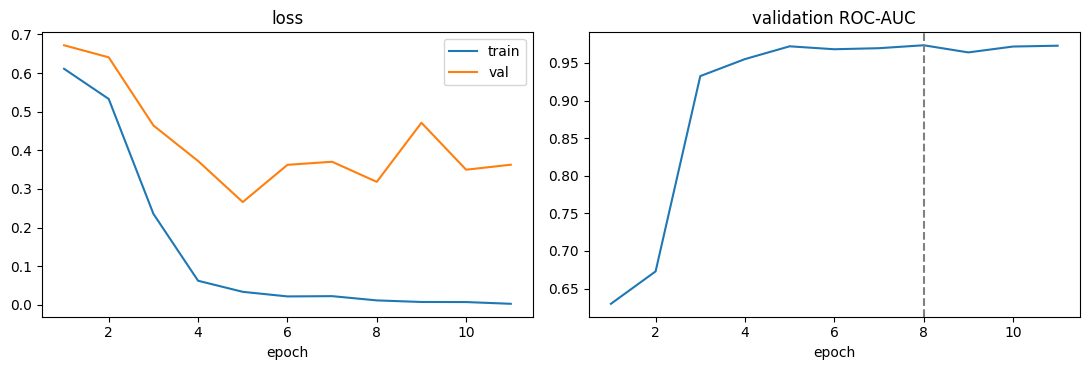

saved: ['best.pt', 'config.json', 'last.pt', 'threshold.json', 'training_curves.png', 'training_log.csv', 'val_predictions.csv']


In [7]:
# ============================================================
# FINAL: best checkpoint -> val predictions -> the ONE decision threshold (chosen on val only)
# ============================================================
dfx_model.load_checkpoint(model, BEST, map_location=device)
ev = evaluate(model, val_loader)

fpr, tpr, thr = roc_curve(ev["labels"], ev["probs"])
j = tpr - fpr
THRESHOLD = float(np.clip(thr[int(np.argmax(j))], 0.0, 1.0))        # Youden's J; thr[0] can be inf
pred = ev["probs"] >= THRESHOLD
val_acc_thr = float((pred == (ev["labels"] > 0.5)).mean())

vp = pd.DataFrame({"face_id": ev["ids"], "label": ev["labels"].astype(int), "prob_fake": ev["probs"]})
vp = vp.merge(val_df[["face_id", "video_id"]], on="face_id", how="left")
video = vp.groupby("video_id").agg(label=("label", "first"), prob=("prob_fake", "mean"))
video_auc = float(roc_auc_score(video["label"], video["prob"])) if video["label"].nunique() == 2 else float("nan")
vp.to_csv(os.path.join(OUT, "val_predictions.csv"), index=False)

print(f"val face-level AUC {ev['auc']:.4f} | video-level AUC {video_auc:.4f} | threshold {THRESHOLD:.4f} | acc at threshold {val_acc_thr:.4f}")

pd.DataFrame(log).to_csv(os.path.join(OUT, "training_log.csv"), index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
L = pd.DataFrame(log)
ax[0].plot(L["epoch"], L["train_loss"], label="train"); ax[0].plot(L["epoch"], L["val_loss"], label="val"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(L["epoch"], L["val_auc"]); ax[1].axvline(best_epoch, ls="--", c="grey"); ax[1].set_title("validation ROC-AUC")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "training_curves.png"), dpi=130); plt.show()

config = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "debug": bool(DEBUG_SUBSET), "debug_subset": DEBUG_SUBSET,
    "model": info, "mean": list(MEAN), "std": list(STD), "label_to_int": dfx_model.LABEL_TO_INT, "positive_class": "FAKE",
    "seed": SEED, "batch_size": BATCH_SIZE, "amp": use_amp, "pos_weight": POS_WEIGHT,
    "stage1": {"epochs": STAGE1_EPOCHS, "lr": STAGE1_LR}, "stage2": {"epochs": STAGE2_EPOCHS, "lr": STAGE2_LR, "weight_decay": WEIGHT_DECAY, "patience": PATIENCE},
    "best_epoch": best_epoch, "best_val_auc": best_auc, "epochs_run": epoch,
    "train_faces": int(len(train_df)), "val_faces": int(len(val_df)),
    "manifest_sha256": meta["manifest_sha256"], "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
    "threshold": {"value": THRESHOLD, "method": "youden_j_on_val", "val_face_auc": ev["auc"], "val_video_auc": video_auc, "val_acc_at_threshold": val_acc_thr},
}
json.dump(config, open(os.path.join(OUT, "config.json"), "w"), indent=2)
json.dump(config["threshold"], open(os.path.join(OUT, "threshold.json"), "w"), indent=2)
print("saved:", sorted(os.listdir(OUT)))
if DEBUG_SUBSET:
    print("\n*** DEBUG RUN: now set DEBUG_SUBSET = None and run again with Save & Run All (Commit) ***")